# 02 · Ridership Patterns: Route 801 Southbound
**Owner: Elijah**

Figures 3–5: hourly demand profile, daily boardings over the six months, and the headway distribution.

## Setup

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import MonthLocator, DateFormatter
from project import load_events, window, new_fig, finish, save, COLORS, SOURCE_NOTE

ev = load_events()
w = window(ev)
# Service day 2021-06-30 holds only 8 records (trips just after midnight), so it is left out of per-day averages.
days = ev[ev.service_day > '2021-06-30']
print(f'ev: {len(ev):,} rows  |  window: {len(w):,} rows  |  service days used: {days.service_day.nunique()}')

ev: 229,414 rows  |  window: 126,070 rows  |  service days used: 183


## Figure 3: Average boardings per day by hour of day

Days: {'Weekday': 131, 'Weekend': 52}
Weekday peak: hour 9, 195.9 avg boardings
Weekday afternoon peak: hour 16, 175.9 avg boardings
Weekend peak: hour 15, 124.6 avg boardings (36% below the weekday peak)
Weekday avg boardings/day: 2514  |  Weekend: 1728  |  weekday is 45% higher


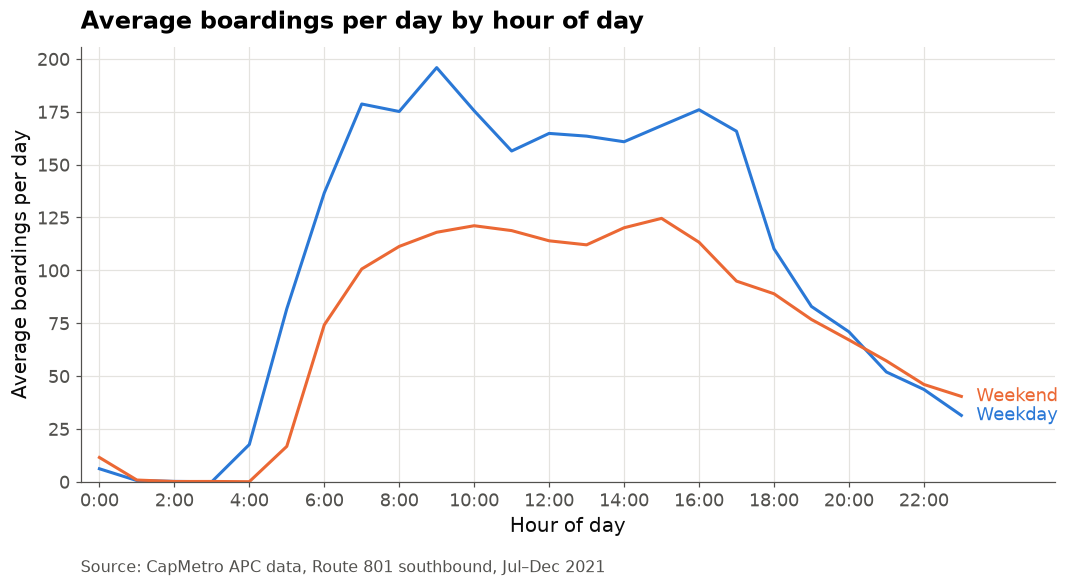

In [2]:
n_days = days.groupby('day_type').service_day.nunique()
bph = (days.groupby(['day_type', 'hour']).ons.sum() / n_days).rename('avg_boardings').reset_index()
wkday = bph[bph.day_type == 'Weekday'].set_index('hour').avg_boardings.reindex(range(24), fill_value=0)
wkend = bph[bph.day_type == 'Weekend'].set_index('hour').avg_boardings.reindex(range(24), fill_value=0)

daily_tot = days.groupby(['service_day', 'day_type']).ons.sum().reset_index()
wd_avg = daily_tot[daily_tot.day_type == 'Weekday'].ons.mean()
we_avg = daily_tot[daily_tot.day_type == 'Weekend'].ons.mean()
pm = wkday.loc[12:23]
print(f'Days: {n_days.to_dict()}')
print(f'Weekday peak: hour {wkday.idxmax()}, {wkday.max():.1f} avg boardings')
print(f'Weekday afternoon peak: hour {pm.idxmax()}, {pm.max():.1f} avg boardings')
print(f'Weekend peak: hour {wkend.idxmax()}, {wkend.max():.1f} avg boardings '
      f'({(1 - wkend.max() / wkday.max()) * 100:.0f}% below the weekday peak)')
print(f'Weekday avg boardings/day: {wd_avg:.0f}  |  Weekend: {we_avg:.0f}  |  weekday is {(wd_avg / we_avg - 1) * 100:.0f}% higher')

fig, ax = new_fig(10, 5.6)
ax.plot(wkday.index, wkday.values, color=COLORS['blue'])
ax.plot(wkend.index, wkend.values, color=COLORS['orange'])
# direct labels at the right end, pushed apart so they never overlap
y_wd, y_we = wkday.iloc[-1], wkend.iloc[-1]
gap = 9
if abs(y_wd - y_we) < gap:
    mid = (y_wd + y_we) / 2
    y_wd, y_we = (mid - gap / 2, mid + gap / 2) if y_wd < y_we else (mid + gap / 2, mid - gap / 2)
ax.text(23.4, y_wd, 'Weekday', color=COLORS['blue'], va='center', fontsize=12)
ax.text(23.4, y_we, 'Weekend', color=COLORS['orange'], va='center', fontsize=12)
ax.set_xticks(range(0, 24, 2), [f'{h}:00' for h in range(0, 24, 2)])
ax.set_xlim(-0.5, 25.5)
ax.set_ylim(0, None)
finish(ax, 'Average boardings per day by hour of day', 'Hour of day', 'Average boardings per day',
       note=SOURCE_NOTE)
fig.tight_layout()
save(fig, 'fig03_boardings_by_hour')
plt.show()

## Figure 4: Total boardings per service day

Overall avg boardings/day: 2291
Weekday avg: 2514 (sd 356)  |  Weekend avg: 1728
Lowest weekday: 1146 on 2021-11-25 (3.8 sd below the weekday mean)
Lowest weekend day: 871 on 2021-12-25
Average weekday boardings by month: {'Jul': 2352.0, 'Aug': 2368.0, 'Sep': 2596.0, 'Oct': 3025.0, 'Nov': 2356.0, 'Dec': 2412.0}


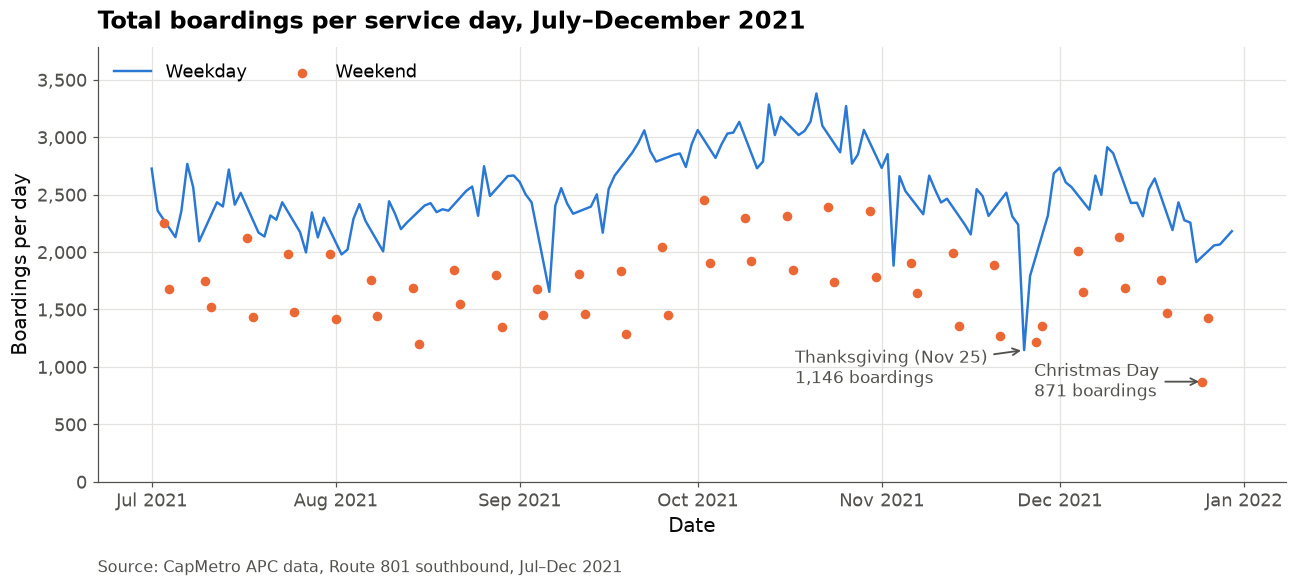

In [3]:
daily_wd = daily_tot[daily_tot.day_type == 'Weekday'].sort_values('service_day')
daily_we = daily_tot[daily_tot.day_type == 'Weekend'].sort_values('service_day')
std_wd = daily_wd.ons.std()
low_wd = daily_wd.loc[daily_wd.ons.idxmin()]
low_we = daily_we.loc[daily_we.ons.idxmin()]
monthly = daily_wd.groupby(daily_wd.service_day.dt.strftime('%b')).ons.mean().reindex(
    ['Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']).round(0)
print(f'Overall avg boardings/day: {daily_tot.ons.mean():.0f}')
print(f'Weekday avg: {wd_avg:.0f} (sd {std_wd:.0f})  |  Weekend avg: {we_avg:.0f}')
print(f'Lowest weekday: {low_wd.ons:.0f} on {low_wd.service_day.date()} '
      f'({(wd_avg - low_wd.ons) / std_wd:.1f} sd below the weekday mean)')
print(f'Lowest weekend day: {low_we.ons:.0f} on {low_we.service_day.date()}')
print('Average weekday boardings by month:', monthly.to_dict())

fig, ax = new_fig(12, 5.6)
ax.plot(daily_wd.service_day, daily_wd.ons, color=COLORS['blue'], linewidth=1.6, label='Weekday')
ax.scatter(daily_we.service_day, daily_we.ons, color=COLORS['orange'], s=28, label='Weekend', zorder=3)
ax.annotate(f'Thanksgiving ({low_wd.service_day:%b %d})\n{low_wd.ons:,.0f} boardings',
            xy=(low_wd.service_day, low_wd.ons), xytext=(-150, -12), textcoords='offset points',
            arrowprops=dict(arrowstyle='->', color=COLORS['muted'], lw=1.2),
            fontsize=11, color=COLORS['muted'], va='center')
ax.annotate(f'Christmas Day\n{low_we.ons:,.0f} boardings',
            xy=(low_we.service_day, low_we.ons), xytext=(-110, 0), textcoords='offset points',
            arrowprops=dict(arrowstyle='->', color=COLORS['muted'], lw=1.2),
            fontsize=11, color=COLORS['muted'], va='center')
ax.legend(loc='upper left', ncol=2)
ax.set_ylim(0, daily_tot.ons.max() * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.xaxis.set_major_locator(MonthLocator())
ax.xaxis.set_major_formatter(DateFormatter('%b %Y'))
finish(ax, 'Total boardings per service day, July–December 2021', 'Date', 'Boardings per day',
       note=SOURCE_NOTE)
fig.tight_layout()
save(fig, 'fig04_daily_boardings')
plt.show()

## Figure 5: Headway distribution (analysis window)

Valid headways: 51,437  |  median 11.0 min
Bunched (<3 min): 5.7%  |  Long gap (>20 min): 10.3%
Most common 1-min bin: 8-9 min (4,123 arrivals); next: [10, 11)
Headways of 40 min or more (not drawn): 177 (0.3%)


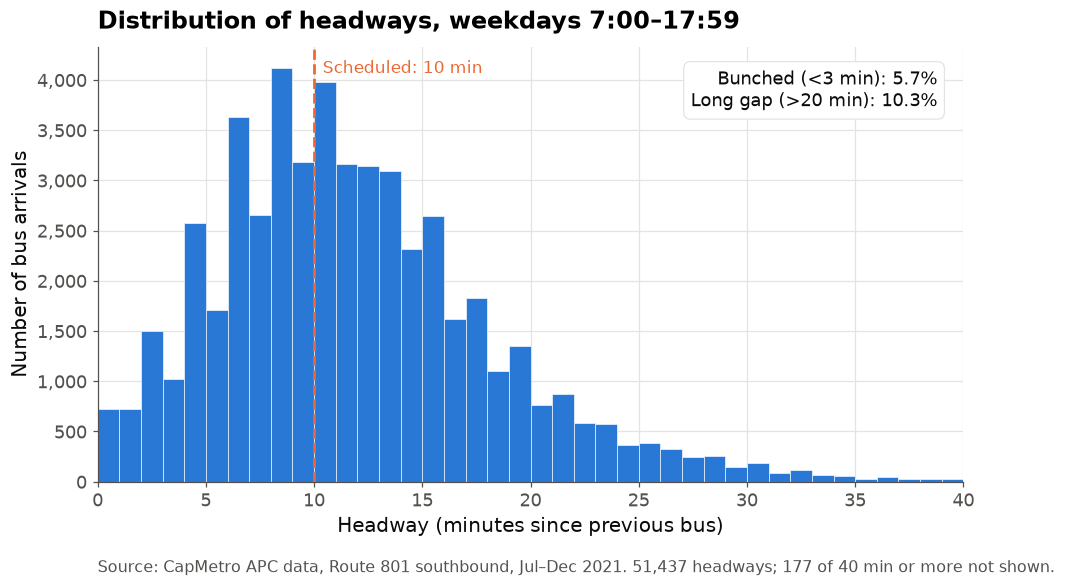

In [4]:
hw = (w.headway_s / 60).dropna()
pct_bunched = (hw < 3).mean() * 100
pct_long = (hw > 20).mean() * 100
counts = pd.cut(hw, range(0, 61), right=False).value_counts()
mode_bin = counts.idxmax()
over40 = (hw >= 40).sum()
print(f'Valid headways: {len(hw):,}  |  median {hw.median():.1f} min')
print(f'Bunched (<3 min): {pct_bunched:.1f}%  |  Long gap (>20 min): {pct_long:.1f}%')
print(f'Most common 1-min bin: {mode_bin.left}-{mode_bin.right} min ({counts.max():,} arrivals); '
      f'next: {counts.sort_values(ascending=False).index[1]}')
print(f'Headways of 40 min or more (not drawn): {over40:,} ({over40 / len(hw) * 100:.1f}%)')

fig, ax = new_fig(10, 5.6)
ax.hist(hw[hw < 40], bins=range(0, 41), color=COLORS['blue'], edgecolor='white', linewidth=0.4)
ax.axvline(10, color=COLORS['orange'], linestyle='--', linewidth=1.8)
ax.text(10.4, ax.get_ylim()[1] * 0.97, 'Scheduled: 10 min', color=COLORS['orange'], fontsize=11, va='top')
ax.text(0.97, 0.95, f'Bunched (<3 min): {pct_bunched:.1f}%\nLong gap (>20 min): {pct_long:.1f}%',
        transform=ax.transAxes, fontsize=11.5, va='top', ha='right', color=COLORS['text'],
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor=COLORS['grid'], linewidth=0.8))
ax.set_xlim(0, 40)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
finish(ax, 'Distribution of headways, weekdays 7:00–17:59', 'Headway (minutes since previous bus)',
       'Number of bus arrivals',
       note=SOURCE_NOTE + f'. {len(hw):,} headways; {over40:,} of 40 min or more not shown.')
fig.tight_layout()
save(fig, 'fig05_headway_distribution')
plt.show()